In [1]:
import torch
from sentence_transformers import SentenceTransformer

# 1. Seleccionar GPU o CPU
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo disponible:", device)

# 2. Cargar MiniLM preentrenado
modelo = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    device=device
)

# 3. Verificar el modelo
print("¡MiniLM cargado correctamente!")
print("Dispositivo del modelo:", modelo.device)
print("Dimensiones de embeddings:", modelo.get_sentence_embedding_dimension())

d:\VIVIAN\Uis\Quinto semestre\Deep Learning\Proyecto Mini-Transforms\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo disponible: cuda


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2225.39it/s]
d:\VIVIAN\Uis\Quinto semestre\Deep Learning\Proyecto Mini-Transforms\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\MSI\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-deve

¡MiniLM cargado correctamente!
Dispositivo del modelo: cuda:0
Dimensiones de embeddings: 384


C:\Users\MSI\AppData\Local\Temp\ipykernel_18352\2829973804.py:18: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Dimensiones de embeddings:", modelo.get_sentence_embedding_dimension())


In [2]:
# Textos de prueba
oraciones = [
    "El asesor cerró el chat sin confirmar la solución.",
    "El agente terminó la conversación sin verificar si resolvió el problema.",
    "El asesor proporcionó información incorrecta sobre el pedido."
]

# Convertir textos en vectores
embeddings = modelo.encode(oraciones)

print("Cantidad de oraciones:", len(embeddings))
print("Forma de los embeddings:", embeddings.shape)

Cantidad de oraciones: 3
Forma de los embeddings: (3, 384)


In [3]:
from sentence_transformers import util

# Calcular similitud entre todas las oraciones
similitudes = util.cos_sim(embeddings, embeddings)

print("MATRIZ DE SIMILITUD SEMÁNTICA\n")

for i in range(len(oraciones)):
    for j in range(len(oraciones)):
        print(
            f"Oración {i+1} vs Oración {j+1}: "
            f"{similitudes[i][j].item():.4f}"
        )
    print()

MATRIZ DE SIMILITUD SEMÁNTICA

Oración 1 vs Oración 1: 1.0000
Oración 1 vs Oración 2: 0.7596
Oración 1 vs Oración 3: 0.5447

Oración 2 vs Oración 1: 0.7596
Oración 2 vs Oración 2: 1.0000
Oración 2 vs Oración 3: 0.4232

Oración 3 vs Oración 1: 0.5447
Oración 3 vs Oración 2: 0.4232
Oración 3 vs Oración 3: 1.0000



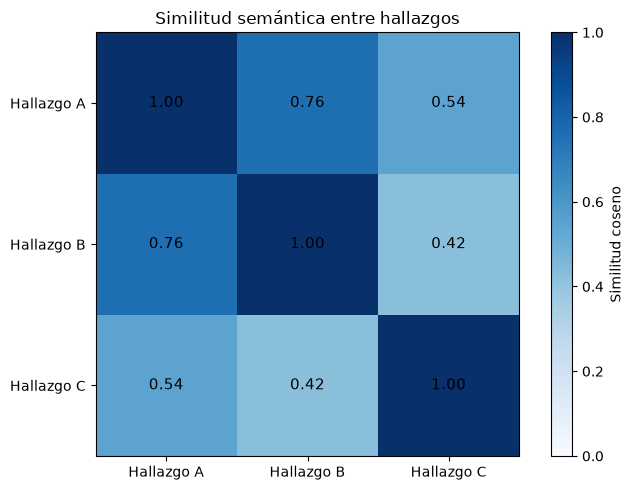

In [5]:
import matplotlib.pyplot as plt
import numpy as np

matriz = similitudes.cpu().numpy()

fig, ax = plt.subplots(figsize=(7, 5))

imagen = ax.imshow(
    matriz,
    cmap="Blues",
    vmin=0,
    vmax=1
)

etiquetas = ["Hallazgo A", "Hallazgo B", "Hallazgo C"]

ax.set_xticks(range(3), etiquetas)
ax.set_yticks(range(3), etiquetas)

for i in range(3):
    for j in range(3):
        ax.text(
            j, i,
            f"{matriz[i, j]:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=11
        )

plt.colorbar(imagen, label="Similitud coseno")
plt.title("Similitud semántica entre hallazgos")
plt.tight_layout()
plt.show()

In [6]:
import pandas as pd

# Base de auditorías de ejemplo
auditorias = pd.DataFrame({
    "hallazgo": [
        "El asesor cerró el chat sin confirmar la solución.",
        "El agente terminó la conversación sin verificar la resolución.",
        "El asesor no preguntó si el cliente necesitaba ayuda adicional.",
        "El agente proporcionó información incorrecta sobre el pedido.",
        "El asesor indicó un procedimiento equivocado al usuario.",
        "El agente no verificó la identidad del cliente.",
        "El asesor omitió validar los datos personales del usuario.",
        "El agente utilizó expresiones poco profesionales."
    ],
    "indicador": [
        "Cierre de interacción",
        "Cierre de interacción",
        "Cierre de interacción",
        "Información incorrecta",
        "Información incorrecta",
        "Validación de identidad",
        "Validación de identidad",
        "Comunicación profesional"
    ]
})

display(auditorias)

,hallazgo,indicador
0,El asesor cerró el chat sin confirmar la soluc...,Cierre de interacción
1,El agente terminó la conversación sin verifica...,Cierre de interacción
2,El asesor no preguntó si el cliente necesitaba...,Cierre de interacción
3,El agente proporcionó información incorrecta s...,Información incorrecta
4,El asesor indicó un procedimiento equivocado a...,Información incorrecta
5,El agente no verificó la identidad del cliente.,Validación de identidad
6,El asesor omitió validar los datos personales ...,Validación de identidad
7,El agente utilizó expresiones poco profesionales.,Comunicación profesional


In [7]:
# Convertir hallazgos históricos en embeddings
embeddings_historicos = modelo.encode(
    auditorias["hallazgo"].tolist(),
    convert_to_tensor=True,
    normalize_embeddings=True
)

print("Embeddings generados correctamente")
print("Dimensiones:", embeddings_historicos.shape)

Embeddings generados correctamente
Dimensiones: torch.Size([8, 384])


In [8]:
from sentence_transformers import util

# Nuevo hallazgo introducido por el auditor
nuevo_hallazgo = (
    "El asesor se despidió sin comprobar "
    "que el problema del usuario estuviera solucionado."
)

# Generar embedding del nuevo hallazgo
embedding_nuevo = modelo.encode(
    nuevo_hallazgo,
    convert_to_tensor=True,
    normalize_embeddings=True
)

# Calcular similitudes
similitudes = util.cos_sim(
    embedding_nuevo,
    embeddings_historicos
)[0]

# Obtener los 3 antecedentes más similares
top_resultados = torch.topk(similitudes, k=3)

print("HALLAZGO ANALIZADO:")
print(nuevo_hallazgo)

print("\nANTECEDENTES MÁS SIMILARES:\n")

for posicion, indice in enumerate(top_resultados.indices, start=1):
    i = indice.item()

    print(f"{posicion}. {auditorias.iloc[i]['hallazgo']}")
    print(f"   Indicador: {auditorias.iloc[i]['indicador']}")
    print(f"   Similitud: {similitudes[i].item():.4f}")
    print()

HALLAZGO ANALIZADO:
El asesor se despidió sin comprobar que el problema del usuario estuviera solucionado.

ANTECEDENTES MÁS SIMILARES:

1. El asesor indicó un procedimiento equivocado al usuario.
   Indicador: Información incorrecta
   Similitud: 0.7247

2. El asesor cerró el chat sin confirmar la solución.
   Indicador: Cierre de interacción
   Similitud: 0.6987

3. El asesor omitió validar los datos personales del usuario.
   Indicador: Validación de identidad
   Similitud: 0.6368

